In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
np.random.seed(42)
X = np.random.rand(100, 1) - 0.5
Y = 3*X[:,0]**2 + 0.05*np.random.randn(100)

In [6]:
df = pd.DataFrame()

In [7]:
df['X'] = X.reshape(100)
df['Y'] = Y

In [8]:
df

,X,Y
0,-0.125460,0.051573
1,0.450714,0.594480
2,0.231994,0.166052
3,0.098658,-0.070178
4,-0.343981,0.343986
...,...,...
95,-0.006204,-0.040675
96,0.022733,-0.002305
97,-0.072459,0.032809
98,-0.474581,0.689516


Text(0.5, 1.0, 'X vs Y')

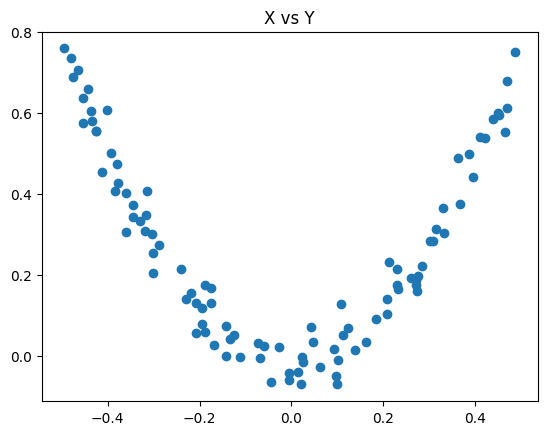

In [9]:
plt.scatter(df['X'], df['Y'])
plt.title('X vs Y')

In [10]:
df['pred1'] = df['Y'].mean()

In [11]:
df

,X,Y,pred1
0,-0.125460,0.051573,0.265458
1,0.450714,0.594480,0.265458
2,0.231994,0.166052,0.265458
3,0.098658,-0.070178,0.265458
4,-0.343981,0.343986,0.265458
...,...,...,...
95,-0.006204,-0.040675,0.265458
96,0.022733,-0.002305,0.265458
97,-0.072459,0.032809,0.265458
98,-0.474581,0.689516,0.265458


In [12]:
df['res1'] = df['Y'] - df['pred1']

In [13]:
df

,X,Y,pred1,res1
0,-0.125460,0.051573,0.265458,-0.213885
1,0.450714,0.594480,0.265458,0.329021
2,0.231994,0.166052,0.265458,-0.099407
3,0.098658,-0.070178,0.265458,-0.335636
4,-0.343981,0.343986,0.265458,0.078528
...,...,...,...,...
95,-0.006204,-0.040675,0.265458,-0.306133
96,0.022733,-0.002305,0.265458,-0.267763
97,-0.072459,0.032809,0.265458,-0.232650
98,-0.474581,0.689516,0.265458,0.424057


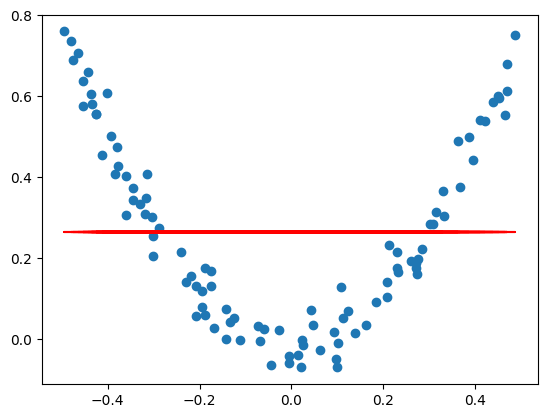

In [14]:
plt.scatter(df['X'], df['Y'])
plt.plot(df['X'], df['pred1'], color = 'red')

In [15]:
from sklearn.tree import DecisionTreeRegressor

In [16]:
tree1 = DecisionTreeRegressor(max_leaf_nodes = 10)

In [17]:
tree1.fit(df['X'].values.reshape(100, 1), df['res1'].values)

DecisionTreeRegressor(max_leaf_nodes=10)

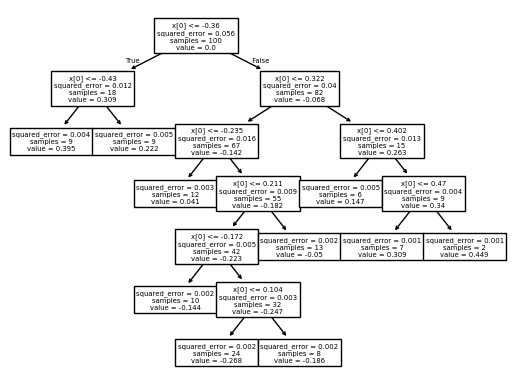

In [18]:
from sklearn.tree import plot_tree
plot_tree(tree1)
plt.show()

In [71]:
# Generating X_test :
X_test = np.linspace(-0.5, 0.5, 500)

In [72]:
Y_pred = 0.265458 + tree1.predict(X_test.reshape(500, 1))

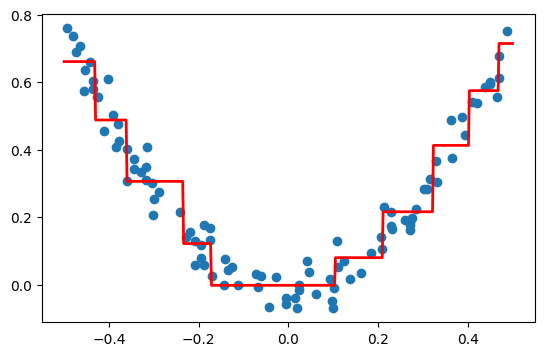

In [73]:
plt.figure(figsize=(14,4))
plt.subplot(121)
plt.plot(X_test, y_pred, linewidth=2,color='red')
plt.scatter(df['X'],df['Y'])

In [55]:
df['pred2'] = 0.265458 + tree1.predict(df['X'].values.reshape(100,1))

In [56]:
df

,X,Y,pred1,res1,pred2,res2
0,-0.125460,0.051573,0.265458,-0.213885,-0.002160,0.053732
1,0.450714,0.594480,0.265458,0.329021,0.574829,0.019651
2,0.231994,0.166052,0.265458,-0.099407,0.215784,-0.049732
3,0.098658,-0.070178,0.265458,-0.335636,-0.002160,-0.068018
4,-0.343981,0.343986,0.265458,0.078528,0.305964,0.038022
...,...,...,...,...,...,...
95,-0.006204,-0.040675,0.265458,-0.306133,-0.002160,-0.038515
96,0.022733,-0.002305,0.265458,-0.267763,-0.002160,-0.000145
97,-0.072459,0.032809,0.265458,-0.232650,-0.002160,0.034968
98,-0.474581,0.689516,0.265458,0.424057,0.660912,0.028604


In [57]:
df['res2'] = df['Y'] - df['pred2']

In [58]:
df

,X,Y,pred1,res1,pred2,res2
0,-0.125460,0.051573,0.265458,-0.213885,-0.002160,0.053732
1,0.450714,0.594480,0.265458,0.329021,0.574829,0.019651
2,0.231994,0.166052,0.265458,-0.099407,0.215784,-0.049732
3,0.098658,-0.070178,0.265458,-0.335636,-0.002160,-0.068018
4,-0.343981,0.343986,0.265458,0.078528,0.305964,0.038022
...,...,...,...,...,...,...
95,-0.006204,-0.040675,0.265458,-0.306133,-0.002160,-0.038515
96,0.022733,-0.002305,0.265458,-0.267763,-0.002160,-0.000145
97,-0.072459,0.032809,0.265458,-0.232650,-0.002160,0.034968
98,-0.474581,0.689516,0.265458,0.424057,0.660912,0.028604


In [59]:
tree2 = DecisionTreeRegressor(max_leaf_nodes = 10)

In [60]:
tree2.fit(df['X'].values.reshape(100, 1), df['res2'].values)

DecisionTreeRegressor(max_leaf_nodes=10)

In [80]:
df_test = pd.DataFrame()
df_test['X_test'] = X_test
df_test['pred2'] = 0.265458 + tree1.predict(X_test.reshape(-1, 1)) + tree2.predict(X_test.reshape(-1, 1))


Text(0.5, 1.0, 'X vs Y')

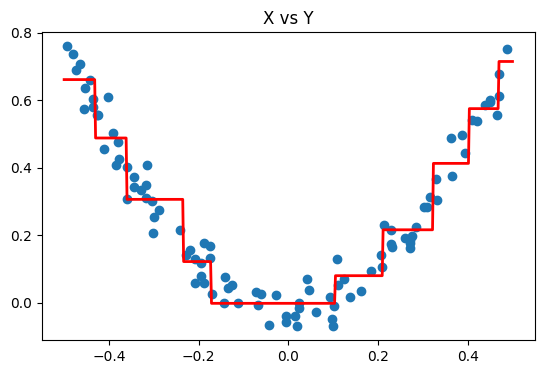

In [81]:
plt.figure(figsize=(14,4))
plt.subplot(121)
plt.plot(X_test, Y_pred, linewidth=2,color='red')
plt.scatter(df['X'],df['Y'])
plt.title('X vs Y')

In [47]:
df['pred2'] = 0.265458 + tree1.predict(df['X'].values.reshape(100, 1))

In [48]:
df

,X,Y,pred1,res1,pred2,res2
0,-0.125460,0.051573,0.265458,-0.213885,-0.002160,0.053732
1,0.450714,0.594480,0.265458,0.329021,0.574829,0.019651
2,0.231994,0.166052,0.265458,-0.099407,0.215784,-0.049732
3,0.098658,-0.070178,0.265458,-0.335636,-0.002160,-0.068018
4,-0.343981,0.343986,0.265458,0.078528,0.305964,0.038022
...,...,...,...,...,...,...
95,-0.006204,-0.040675,0.265458,-0.306133,-0.002160,-0.038515
96,0.022733,-0.002305,0.265458,-0.267763,-0.002160,-0.000145
97,-0.072459,0.032809,0.265458,-0.232650,-0.002160,0.034968
98,-0.474581,0.689516,0.265458,0.424057,0.660912,0.028604


In [50]:
df['res2'] = df['Y'] - df['pred2']

In [51]:
df

,X,Y,pred1,res1,pred2,res2
0,-0.125460,0.051573,0.265458,-0.213885,-0.002160,0.053732
1,0.450714,0.594480,0.265458,0.329021,0.574829,0.019651
2,0.231994,0.166052,0.265458,-0.099407,0.215784,-0.049732
3,0.098658,-0.070178,0.265458,-0.335636,-0.002160,-0.068018
4,-0.343981,0.343986,0.265458,0.078528,0.305964,0.038022
...,...,...,...,...,...,...
95,-0.006204,-0.040675,0.265458,-0.306133,-0.002160,-0.038515
96,0.022733,-0.002305,0.265458,-0.267763,-0.002160,-0.000145
97,-0.072459,0.032809,0.265458,-0.232650,-0.002160,0.034968
98,-0.474581,0.689516,0.265458,0.424057,0.660912,0.028604


In [52]:
tree2 = DecisionTreeRegressor(max_leaf_nodes=10)

In [86]:
def gradient_boost(X, y, number, lr, count=1, regs=[], foo=None):

  if number == 0:
    return 
  else:
    # do gradient boosting

    if count > 1:
      y = y - regs[-1].predict(X)
    else:
      foo = y

    tree_reg = DecisionTreeRegressor(max_depth=5, random_state=42)
    tree_reg.fit(X, y)

    regs.append(tree_reg)

    x1 = np.linspace(-0.5, 0.5, 500)
    y_pred = sum(lr * regressor.predict(x1.reshape(-1, 1)) for regressor in regs)

    print(number)
    plt.figure()
    plt.plot(x1, y_pred, linewidth=2)
    plt.plot(X[:, 0], foo,"r.")
    plt.show()

    gradient_boost(X,y,number-1,lr,count+1,regs,foo=foo)


5


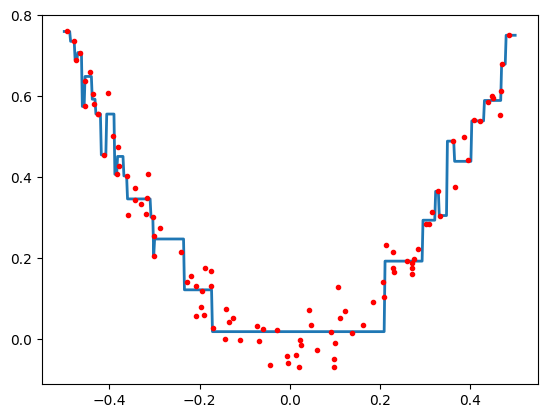

4


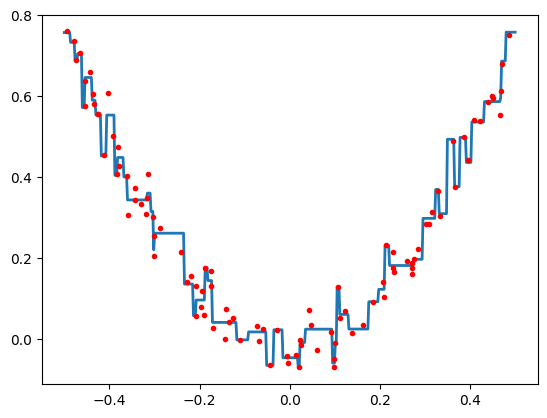

3


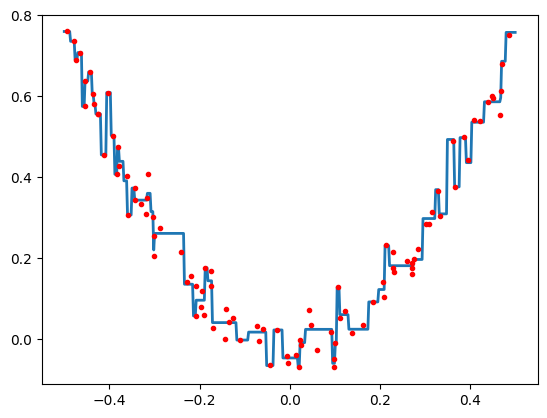

2


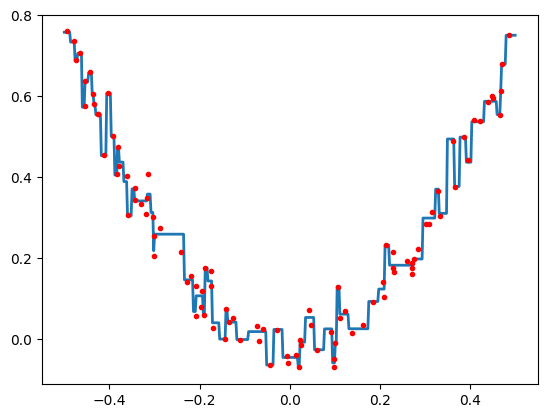

1


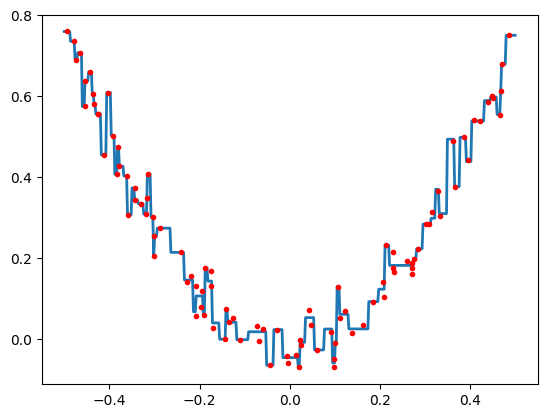

In [87]:
np.random.seed(42)
X = np.random.rand(100, 1) - 0.5
y = 3*X[:, 0]**2 + 0.05 * np.random.randn(100)
gradient_boost(X,y,5,lr=1)